# Question 2 – Working with Pandas DataFrames
## Scenario: Retail Transaction and Revenue Analytics

The dataset has 20 retail transactions across product categories and regions.

| Task | Description | Marks |
|---|---|---|
| a | Create a DataFrame; inspect structure, data types, dimensions, summary statistics | 10 |
| b | Check missing values, duplicates, invalid records, inconsistent data types | 10 |
| c | Derived columns: gross sales, discount amount, net sales | 15 |
| d | Product-wise, category-wise and region-wise aggregations | 15 |
| e | Pivot tables of net sales across regions and categories | 15 |
| f | Rank transactions; top products and regions | 10 |
| g | Comparative visualizations for sales and discounts | 15 |
| h | Interpretation and business recommendations | 10 |

> **How to use:** run all cells from top to bottom. The notebook works in Jupyter and Google Colab without installing anything.
>
> **Exam tip:** if the exam uses different data, edit only the dictionary in Step 0.

## Step 0 – Import libraries and display settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)   # 1,234,567.89 style numbers

## (a) Create the DataFrame and inspect it  *(10 marks)*

A DataFrame is built from a dictionary: **keys = column names**, **values = lists of column values**. Short, code-friendly column names (no spaces or symbols) make the code easier to write. `Unit_Price` is in ₹ and `Discount_Pct` is in %.

In [2]:
data = {
    "ID":           ["T101","T102","T103","T104","T105","T106","T107","T108","T109","T110",
                     "T111","T112","T113","T114","T115","T116","T117","T118","T119","T120"],
    "Product":      ["Laptop","Mobile","Chair","Table","Laptop","Mobile","Chair","Table","Mobile","Laptop",
                     "Tablet","Sofa","Tablet","Sofa","Chair","Laptop","Mobile","Table","Tablet","Sofa"],
    "Category":     ["Electronics","Electronics","Furniture","Furniture","Electronics","Electronics","Furniture",
                     "Furniture","Electronics","Electronics","Electronics","Furniture","Electronics","Furniture",
                     "Furniture","Electronics","Electronics","Furniture","Electronics","Furniture"],
    "Region":       ["South","North","South","East","West","South","North","West","East","East",
                     "South","North","West","South","East","North","West","South","North","East"],
    "Units":        [12, 25, 30, 15, 10, 20, 18, 22, 16, 8, 14, 6, 11, 9, 24, 7, 19, 17, 13, 5],
    "Unit_Price":   [55000, 18000, 3500, 7000, 55000, 18000, 3500, 7000, 18000, 55000,
                     25000, 32000, 25000, 32000, 3500, 55000, 18000, 7000, 25000, 32000],
    "Discount_Pct": [10, 5, 0, 10, 5, 15, 5, 10, 0, 15, 10, 5, 0, 15, 10, 5, 10, 0, 5, 10],
}
df = pd.DataFrame(data)
df

,ID,Product,Category,Region,Units,Unit_Price,Discount_Pct
0,T101,Laptop,Electronics,South,12,55000,10
1,T102,Mobile,Electronics,North,25,18000,5
2,T103,Chair,Furniture,South,30,3500,0
3,T104,Table,Furniture,East,15,7000,10
4,T105,Laptop,Electronics,West,10,55000,5
5,T106,Mobile,Electronics,South,20,18000,15
6,T107,Chair,Furniture,North,18,3500,5
7,T108,Table,Furniture,West,22,7000,10
8,T109,Mobile,Electronics,East,16,18000,0
9,T110,Laptop,Electronics,East,8,55000,15


In [3]:
print("Dimensions (rows, columns):", df.shape)
print("Number of dimensions      :", df.ndim)
print("Total cells (size)        :", df.size)
print("Column names              :", list(df.columns))
print("\nData type of each column:")
print(df.dtypes)

Dimensions (rows, columns): (20, 7)
Number of dimensions      : 2
Total cells (size)        : 140
Column names              : ['ID', 'Product', 'Category', 'Region', 'Units', 'Unit_Price', 'Discount_Pct']

Data type of each column:
ID                str
Product           str
Category          str
Region            str
Units           int64
Unit_Price      int64
Discount_Pct    int64
dtype: object


In [4]:
# info() = structure summary: column names, non-null counts, data types and memory
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   ID            20 non-null     str  
 1   Product       20 non-null     str  
 2   Category      20 non-null     str  
 3   Region        20 non-null     str  
 4   Units         20 non-null     int64
 5   Unit_Price    20 non-null     int64
 6   Discount_Pct  20 non-null     int64
dtypes: int64(3), str(4)
memory usage: 1.2 KB


In [5]:
# First and last rows - quick look at the data
display(df.head(3))
display(df.tail(3))

,ID,Product,Category,Region,Units,Unit_Price,Discount_Pct
0,T101,Laptop,Electronics,South,12,55000,10
1,T102,Mobile,Electronics,North,25,18000,5
2,T103,Chair,Furniture,South,30,3500,0


,ID,Product,Category,Region,Units,Unit_Price,Discount_Pct
17,T118,Table,Furniture,South,17,7000,0
18,T119,Tablet,Electronics,North,13,25000,5
19,T120,Sofa,Furniture,East,5,32000,10


In [6]:
# Summary statistics for numeric columns (count, mean, std, min, quartiles, max)
display(df.describe())

# Summary for the text columns (count, number of unique values, most frequent value and its frequency).
# exclude="number" works in every pandas version (pandas 3 stores text as 'str', not 'object').
display(df.describe(exclude="number"))

,Units,Unit_Price,Discount_Pct
count,20.00,20.00,20.00
mean,15.05,"24,725.00",7.25
std,6.86,"18,209.65",4.99
min,5.00,"3,500.00",0.00
25%,9.75,"7,000.00",5.00
50%,14.50,"21,500.00",7.50
75%,19.25,"32,000.00",10.00
max,30.00,"55,000.00",15.00


,ID,Product,Category,Region
count,20,20,20,20
unique,20,6,2,4
top,T101,Laptop,Electronics,South
freq,1,4,11,6


In [7]:
# How many transactions per category / region / product
for col in ["Category", "Region", "Product"]:
    print(df[col].value_counts().to_string(), "\n")

Category
Electronics    11
Furniture       9 

Region
South    6
North    5
East     5
West     4 

Product
Laptop    4
Mobile    4
Chair     3
Table     3
Tablet    3
Sofa      3 



## (b) Data quality checks  *(10 marks)*

We check four things:
1. **Missing values** – `isnull().sum()`.
2. **Duplicate transactions** – fully repeated rows, and repeated transaction IDs.
3. **Invalid records** – units ≤ 0, price ≤ 0, discount outside 0–100 %, a product mapped to two categories, or the same product with two different prices.
4. **Inconsistent data types / text** – numbers stored as text, extra spaces or mixed case in categories.

In [8]:
print("1. Missing values per column:")
print(df.isnull().sum())
print("   Total missing:", df.isnull().sum().sum())

1. Missing values per column:
ID              0
Product         0
Category        0
Region          0
Units           0
Unit_Price      0
Discount_Pct    0
dtype: int64
   Total missing: 0


In [9]:
print("2. Fully duplicated rows      :", df.duplicated().sum())
print("   Duplicated transaction IDs:", df["ID"].duplicated().sum())
print("   Is ID a unique key?        :", df["ID"].is_unique)

2. Fully duplicated rows      : 0
   Duplicated transaction IDs: 0
   Is ID a unique key?        : True


In [10]:
invalid_units = df[df["Units"] <= 0]
invalid_price = df[df["Unit_Price"] <= 0]
invalid_disc  = df[(df["Discount_Pct"] < 0) | (df["Discount_Pct"] > 100)]
print("3. Rows with units <= 0             :", len(invalid_units))
print("   Rows with price <= 0             :", len(invalid_price))
print("   Rows with discount outside 0-100 :", len(invalid_disc))

# Each product should belong to exactly one category and have exactly one list price
print("\n   Categories per product:", df.groupby("Product")["Category"].nunique().to_dict())
print("   Prices per product    :", df.groupby("Product")["Unit_Price"].nunique().to_dict())
print("   Valid ID format (T + 3 digits)?", df["ID"].str.fullmatch(r"T\d{3}").all())

3. Rows with units <= 0             : 0
   Rows with price <= 0             : 0
   Rows with discount outside 0-100 : 0

   Categories per product: {'Chair': 1, 'Laptop': 1, 'Mobile': 1, 'Sofa': 1, 'Table': 1, 'Tablet': 1}
   Prices per product    : {'Chair': 1, 'Laptop': 1, 'Mobile': 1, 'Sofa': 1, 'Table': 1, 'Tablet': 1}
   Valid ID format (T + 3 digits)? True


In [11]:
print("4. Numeric columns really numeric?")
for col in ["Units", "Unit_Price", "Discount_Pct"]:
    print(f"   {col:13s}: {df[col].dtype}  numeric = {pd.api.types.is_numeric_dtype(df[col])}")

print("\n   Distinct text values (look for spelling/case/space problems):")
for col in ["Product", "Category", "Region"]:
    print(f"   {col:9s}: {sorted(df[col].unique())}")

4. Numeric columns really numeric?
   Units        : int64  numeric = True
   Unit_Price   : int64  numeric = True
   Discount_Pct : int64  numeric = True

   Distinct text values (look for spelling/case/space problems):
   Product  : ['Chair', 'Laptop', 'Mobile', 'Sofa', 'Table', 'Tablet']
   Category : ['Electronics', 'Furniture']
   Region   : ['East', 'North', 'South', 'West']


**Result:** the dataset is **clean**. It has no missing values, no duplicates, no invalid numbers and consistent categories, and all numeric columns have integer types. No cleaning is needed.

### Exam backup: how to clean a dirty version
Exam data may contain problems on purpose. The cell below shows the usual fixes on a **copy** with deliberately added errors. The original `df` is not changed.

In [12]:
dirty = df.head(5).copy()
dirty["Units"] = dirty["Units"].astype(object)            # allow mixed values for the demo
dirty["Discount_Pct"] = dirty["Discount_Pct"].astype(float)  # float column so it can hold NaN
dirty.loc[1, "Units"] = "25"          # number stored as text
dirty.loc[2, "Region"] = " south "    # extra spaces + wrong case
dirty.loc[3, "Discount_Pct"] = np.nan # missing value
dirty.loc[4, "Units"] = -10           # invalid negative quantity
dirty = pd.concat([dirty, dirty.iloc[[0]]], ignore_index=True)   # duplicate row
print("Dirty data:")
display(dirty)

clean = dirty.copy()
clean = clean.drop_duplicates()                                      # remove duplicate rows
clean["Units"] = pd.to_numeric(clean["Units"], errors="coerce")      # text -> number (bad text -> NaN)
clean["Region"] = clean["Region"].str.strip().str.title()            # ' south ' -> 'South'
clean["Discount_Pct"] = clean["Discount_Pct"].fillna(0)              # assume no discount if missing (state your assumption!)
clean = clean[clean["Units"] > 0]                                    # drop invalid quantities
clean["Units"] = clean["Units"].astype(int)
print("After cleaning:")
display(clean)
print(clean.dtypes)

Dirty data:


,ID,Product,Category,Region,Units,Unit_Price,Discount_Pct
0,T101,Laptop,Electronics,South,12,55000,10.00
1,T102,Mobile,Electronics,North,25,18000,5.00
2,T103,Chair,Furniture,south,30,3500,0.00
3,T104,Table,Furniture,East,15,7000,NaN
4,T105,Laptop,Electronics,West,-10,55000,5.00
5,T101,Laptop,Electronics,South,12,55000,10.00


After cleaning:


,ID,Product,Category,Region,Units,Unit_Price,Discount_Pct
0,T101,Laptop,Electronics,South,12,55000,10.00
1,T102,Mobile,Electronics,North,25,18000,5.00
2,T103,Chair,Furniture,South,30,3500,0.00
3,T104,Table,Furniture,East,15,7000,0.00


ID                  str
Product             str
Category            str
Region              str
Units             int64
Unit_Price        int64
Discount_Pct    float64
dtype: object


## (c) Derived columns  *(15 marks)*

$$\text{Gross Sales} = \text{Units} \times \text{Unit Price}$$
$$\text{Discount Amount} = \text{Gross Sales} \times \frac{\text{Discount \%}}{100}$$
$$\text{Net Sales} = \text{Gross Sales} - \text{Discount Amount}$$

These are **vectorized** column operations: each formula is applied to all 20 rows at once.

In [13]:
df["Gross_Sales"] = df["Units"] * df["Unit_Price"]
df["Discount_Amt"] = df["Gross_Sales"] * df["Discount_Pct"] / 100
df["Net_Sales"] = df["Gross_Sales"] - df["Discount_Amt"]

display(df)

,ID,Product,Category,Region,Units,Unit_Price,Discount_Pct,Gross_Sales,Discount_Amt,Net_Sales
0,T101,Laptop,Electronics,South,12,55000,10,660000,"66,000.00","594,000.00"
1,T102,Mobile,Electronics,North,25,18000,5,450000,"22,500.00","427,500.00"
2,T103,Chair,Furniture,South,30,3500,0,105000,0.00,"105,000.00"
3,T104,Table,Furniture,East,15,7000,10,105000,"10,500.00","94,500.00"
4,T105,Laptop,Electronics,West,10,55000,5,550000,"27,500.00","522,500.00"
5,T106,Mobile,Electronics,South,20,18000,15,360000,"54,000.00","306,000.00"
6,T107,Chair,Furniture,North,18,3500,5,63000,"3,150.00","59,850.00"
7,T108,Table,Furniture,West,22,7000,10,154000,"15,400.00","138,600.00"
8,T109,Mobile,Electronics,East,16,18000,0,288000,0.00,"288,000.00"
9,T110,Laptop,Electronics,East,8,55000,15,440000,"66,000.00","374,000.00"


In [14]:
# Check: net sales must equal gross x (1 - discount%)
check = np.allclose(df["Net_Sales"], df["Gross_Sales"] * (1 - df["Discount_Pct"] / 100))
print("Net sales formula verified:", check)

tot_gross, tot_disc, tot_net = df[["Gross_Sales", "Discount_Amt", "Net_Sales"]].sum()
print(f"\nTotal gross sales   : ₹{tot_gross:,.0f}")
print(f"Total discount given: ₹{tot_disc:,.0f}  ({tot_disc / tot_gross * 100:.2f}% of gross)")
print(f"Total net sales     : ₹{tot_net:,.0f}")

Net sales formula verified: True

Total gross sales   : ₹5,695,000
Total discount given: ₹446,950  (7.85% of gross)
Total net sales     : ₹5,248,050


## (d) Product-wise, category-wise and region-wise aggregations  *(15 marks)*

`groupby()` splits the rows into groups, then `agg()` calculates several statistics for each group. A **named aggregation** (`new_name=("column", "function")`) gives readable column names.

In [15]:
def summarise(by):
    g = df.groupby(by).agg(
        Transactions=("ID", "count"),
        Units=("Units", "sum"),
        Gross_Sales=("Gross_Sales", "sum"),
        Discount_Amt=("Discount_Amt", "sum"),
        Net_Sales=("Net_Sales", "sum"),
        Avg_Net_per_Txn=("Net_Sales", "mean"),
        Avg_Discount_Pct=("Discount_Pct", "mean"),
    )
    g["Effective_Disc_%"] = g["Discount_Amt"] / g["Gross_Sales"] * 100   # discount weighted by sales value
    g["Share_of_Net_%"] = g["Net_Sales"] / g["Net_Sales"].sum() * 100
    return g.sort_values("Net_Sales", ascending=False)

product_summary = summarise("Product")
print("PRODUCT-WISE")
display(product_summary)

PRODUCT-WISE


,Transactions,Units,Gross_Sales,Discount_Amt,Net_Sales,Avg_Net_per_Txn,Avg_Discount_Pct,Effective_Disc_%,Share_of_Net_%
Product,,,,,,,,,
Laptop,4,37,2035000,"178,750.00","1,856,250.00","464,062.50",8.75,8.78,35.37
Mobile,4,80,1440000,"110,700.00","1,329,300.00","332,325.00",7.50,7.69,25.33
Tablet,3,38,950000,"51,250.00","898,750.00","299,583.33",5.00,5.39,17.13
Sofa,3,20,640000,"68,800.00","571,200.00","190,400.00",10.00,10.75,10.88
Table,3,54,378000,"25,900.00","352,100.00","117,366.67",6.67,6.85,6.71
Chair,3,72,252000,"11,550.00","240,450.00","80,150.00",5.00,4.58,4.58


In [16]:
category_summary = summarise("Category")
print("CATEGORY-WISE")
display(category_summary)

CATEGORY-WISE


,Transactions,Units,Gross_Sales,Discount_Amt,Net_Sales,Avg_Net_per_Txn,Avg_Discount_Pct,Effective_Disc_%,Share_of_Net_%
Category,,,,,,,,,
Electronics,11,155,4425000,"340,700.00","4,084,300.00","371,300.00",7.27,7.70,77.83
Furniture,9,146,1270000,"106,250.00","1,163,750.00","129,305.56",7.22,8.37,22.17


In [17]:
region_summary = summarise("Region")
print("REGION-WISE")
display(region_summary)

REGION-WISE


,Transactions,Units,Gross_Sales,Discount_Amt,Net_Sales,Avg_Net_per_Txn,Avg_Discount_Pct,Effective_Disc_%,Share_of_Net_%
Region,,,,,,,,,
South,6,102,1882000,"198,200.00","1,683,800.00","280,633.33",8.33,10.53,32.08
North,5,69,1415000,"70,750.00","1,344,250.00","268,850.00",5.00,5.00,25.61
West,4,62,1321000,"77,100.00","1,243,900.00","310,975.00",6.25,5.84,23.70
East,5,68,1077000,"100,900.00","976,100.00","195,220.00",9.00,9.37,18.60


> **Average discount % vs effective discount %.** `Avg_Discount_Pct` is the simple average of the discount rates. `Effective_Disc_%` = total discount ÷ total gross sales, so large orders count more. The effective rate shows how much revenue was actually given away.

In [18]:
# Two-level grouping: category within region
display(df.groupby(["Region", "Category"])["Net_Sales"].sum().unstack())

Category,Electronics,Furniture
Region,,
East,"662,000.00","314,100.00"
North,"1,102,000.00","242,250.00"
South,"1,215,000.00","468,800.00"
West,"1,105,300.00","138,600.00"


## (e) Pivot tables  *(15 marks)*

`pd.pivot_table()` reshapes the data: **index** → rows, **columns** → columns, **values** → the number in each cell, and **aggfunc** → how values are combined. `margins=True` adds row and column totals (labelled *Total*). `fill_value=0` shows 0 where a combination has no sales.

In [19]:
pivot_net = pd.pivot_table(df, values="Net_Sales", index="Region", columns="Category",
                           aggfunc="sum", margins=True, margins_name="Total", fill_value=0)
print("Net sales (₹) by Region x Category")
display(pivot_net)

Net sales (₹) by Region x Category


Category,Electronics,Furniture,Total
Region,,,
East,"662,000.00","314,100.00","976,100.00"
North,"1,102,000.00","242,250.00","1,344,250.00"
South,"1,215,000.00","468,800.00","1,683,800.00"
West,"1,105,300.00","138,600.00","1,243,900.00"
Total,"4,084,300.00","1,163,750.00","5,248,050.00"


In [20]:
# Same pivot as percentage of the grand total
pivot_pct = pivot_net / pivot_net.loc["Total", "Total"] * 100
print("Share of total net sales (%)")
display(pivot_pct.round(2))

Share of total net sales (%)


Category,Electronics,Furniture,Total
Region,,,
East,12.61,5.99,18.60
North,21.00,4.62,25.61
South,23.15,8.93,32.08
West,21.06,2.64,23.70
Total,77.83,22.17,100.00


In [21]:
pivot_prod = pd.pivot_table(df, values="Net_Sales", index="Product", columns="Region",
                            aggfunc="sum", margins=True, margins_name="Total", fill_value=0)
print("Net sales (₹) by Product x Region")
display(pivot_prod)

Net sales (₹) by Product x Region


Region,East,North,South,West,Total
Product,,,,,
Chair,"75,600.00","59,850.00","105,000.00",0.00,"240,450.00"
Laptop,"374,000.00","365,750.00","594,000.00","522,500.00","1,856,250.00"
Mobile,"288,000.00","427,500.00","306,000.00","307,800.00","1,329,300.00"
Sofa,"144,000.00","182,400.00","244,800.00",0.00,"571,200.00"
Table,"94,500.00",0.00,"119,000.00","138,600.00","352,100.00"
Tablet,0.00,"308,750.00","315,000.00","275,000.00","898,750.00"
Total,"976,100.00","1,344,250.00","1,683,800.00","1,243,900.00","5,248,050.00"


In [22]:
# Several statistics at once: total net sales, total units and average discount %
pivot_multi = pd.pivot_table(df, index="Region", columns="Category",
                             values=["Net_Sales", "Units", "Discount_Pct"],
                             aggfunc={"Net_Sales": "sum", "Units": "sum", "Discount_Pct": "mean"})
display(pivot_multi)

Discount_Pct              Net_Sales                  Units          
Category  Electronics Furniture  Electronics  Furniture Electronics Furniture
Region                                                                       
East             7.50     10.00   662,000.00 314,100.00          24        44
North            5.00      5.00 1,102,000.00 242,250.00          45        24
South           11.67      5.00 1,215,000.00 468,800.00          46        56
West             5.00     10.00 1,105,300.00 138,600.00          40        22

## (f) Ranking transactions; top products and regions  *(10 marks)*

`rank(ascending=False)` gives rank 1 to the largest value. `method="min"` gives tied values the same (best) rank, as in sports rankings (1, 2, 2, 4).

In [23]:
df["Rank_Net"] = df["Net_Sales"].rank(ascending=False, method="min").astype(int)
df["Rank_in_Category"] = df.groupby("Category")["Net_Sales"].rank(ascending=False, method="min").astype(int)

ranked = df.sort_values("Rank_Net")[["Rank_Net", "ID", "Product", "Category", "Region", "Units",
                                     "Discount_Pct", "Net_Sales", "Rank_in_Category"]]
display(ranked)

,Rank_Net,ID,Product,Category,Region,Units,Discount_Pct,Net_Sales,Rank_in_Category
0,1,T101,Laptop,Electronics,South,12,10,"594,000.00",1
4,2,T105,Laptop,Electronics,West,10,5,"522,500.00",2
1,3,T102,Mobile,Electronics,North,25,5,"427,500.00",3
9,4,T110,Laptop,Electronics,East,8,15,"374,000.00",4
15,5,T116,Laptop,Electronics,North,7,5,"365,750.00",5
10,6,T111,Tablet,Electronics,South,14,10,"315,000.00",6
18,7,T119,Tablet,Electronics,North,13,5,"308,750.00",7
16,8,T117,Mobile,Electronics,West,19,10,"307,800.00",8
5,9,T106,Mobile,Electronics,South,20,15,"306,000.00",9
8,10,T109,Mobile,Electronics,East,16,0,"288,000.00",10


In [24]:
print("Top 5 transactions by net sales:")
display(df.nlargest(5, "Net_Sales")[["ID", "Product", "Region", "Units", "Net_Sales"]])
print("Bottom 5 transactions by net sales:")
display(df.nsmallest(5, "Net_Sales")[["ID", "Product", "Region", "Units", "Net_Sales"]])

Top 5 transactions by net sales:


,ID,Product,Region,Units,Net_Sales
0,T101,Laptop,South,12,"594,000.00"
4,T105,Laptop,West,10,"522,500.00"
1,T102,Mobile,North,25,"427,500.00"
9,T110,Laptop,East,8,"374,000.00"
15,T116,Laptop,North,7,"365,750.00"


Bottom 5 transactions by net sales:


,ID,Product,Region,Units,Net_Sales
6,T107,Chair,North,18,"59,850.00"
14,T115,Chair,East,24,"75,600.00"
3,T104,Table,East,15,"94,500.00"
2,T103,Chair,South,30,"105,000.00"
17,T118,Table,South,17,"119,000.00"


In [25]:
top_product = product_summary.index[0]
top_region = region_summary.index[0]
print(f"Top product by net sales : {top_product} (₹{product_summary.loc[top_product, 'Net_Sales']:,.0f}, "
      f"{product_summary.loc[top_product, 'Share_of_Net_%']:.1f}% of total)")
print(f"Top region by net sales  : {top_region} (₹{region_summary.loc[top_region, 'Net_Sales']:,.0f}, "
      f"{region_summary.loc[top_region, 'Share_of_Net_%']:.1f}% of total)")
print(f"Top product by units sold: {product_summary['Units'].idxmax()} ({product_summary['Units'].max()} units)")

# Best product in each region
best_in_region = df.loc[df.groupby("Region")["Net_Sales"].idxmax(), ["Region", "Product", "ID", "Net_Sales"]]
print("\nBest-selling transaction in each region:")
display(best_in_region.set_index("Region"))

Top product by net sales : Laptop (₹1,856,250, 35.4% of total)
Top region by net sales  : South (₹1,683,800, 32.1% of total)
Top product by units sold: Mobile (80 units)

Best-selling transaction in each region:


,Product,ID,Net_Sales
Region,,,
East,Laptop,T110,"374,000.00"
North,Mobile,T102,"427,500.00"
South,Laptop,T101,"594,000.00"
West,Laptop,T105,"522,500.00"


In [26]:
# Product and region ranks in one table
display(pd.DataFrame({
    "Product rank": product_summary["Net_Sales"].rank(ascending=False).astype(int),
    "Net sales (₹)": product_summary["Net_Sales"],
}))
display(pd.DataFrame({
    "Region rank": region_summary["Net_Sales"].rank(ascending=False).astype(int),
    "Net sales (₹)": region_summary["Net_Sales"],
}))

,Product rank,Net sales (₹)
Product,,
Laptop,1,"1,856,250.00"
Mobile,2,"1,329,300.00"
Tablet,3,"898,750.00"
Sofa,4,"571,200.00"
Table,5,"352,100.00"
Chair,6,"240,450.00"


,Region rank,Net sales (₹)
Region,,
South,1,"1,683,800.00"
North,2,"1,344,250.00"
West,3,"1,243,900.00"
East,4,"976,100.00"


## (g) Comparative visualizations for sales and discounts  *(15 marks)*

Sales values are in the millions, so they are plotted in **₹ lakh** (1 lakh = 100,000) to keep axis labels short.

| Plot | Purpose |
|---|---|
| Grouped bar: gross vs net by product | revenue per product and how much the discount removes |
| Grouped bar: region × category | the pivot table from (e) as a picture |
| Stacked bar: net + discount by region | how gross sales split into kept revenue and discount |
| Pie: share of net sales by category | proportions |
| Bar: effective discount % by product/region | where discounts are concentrated |
| Scatter: discount % vs units | whether bigger discounts sold more units |

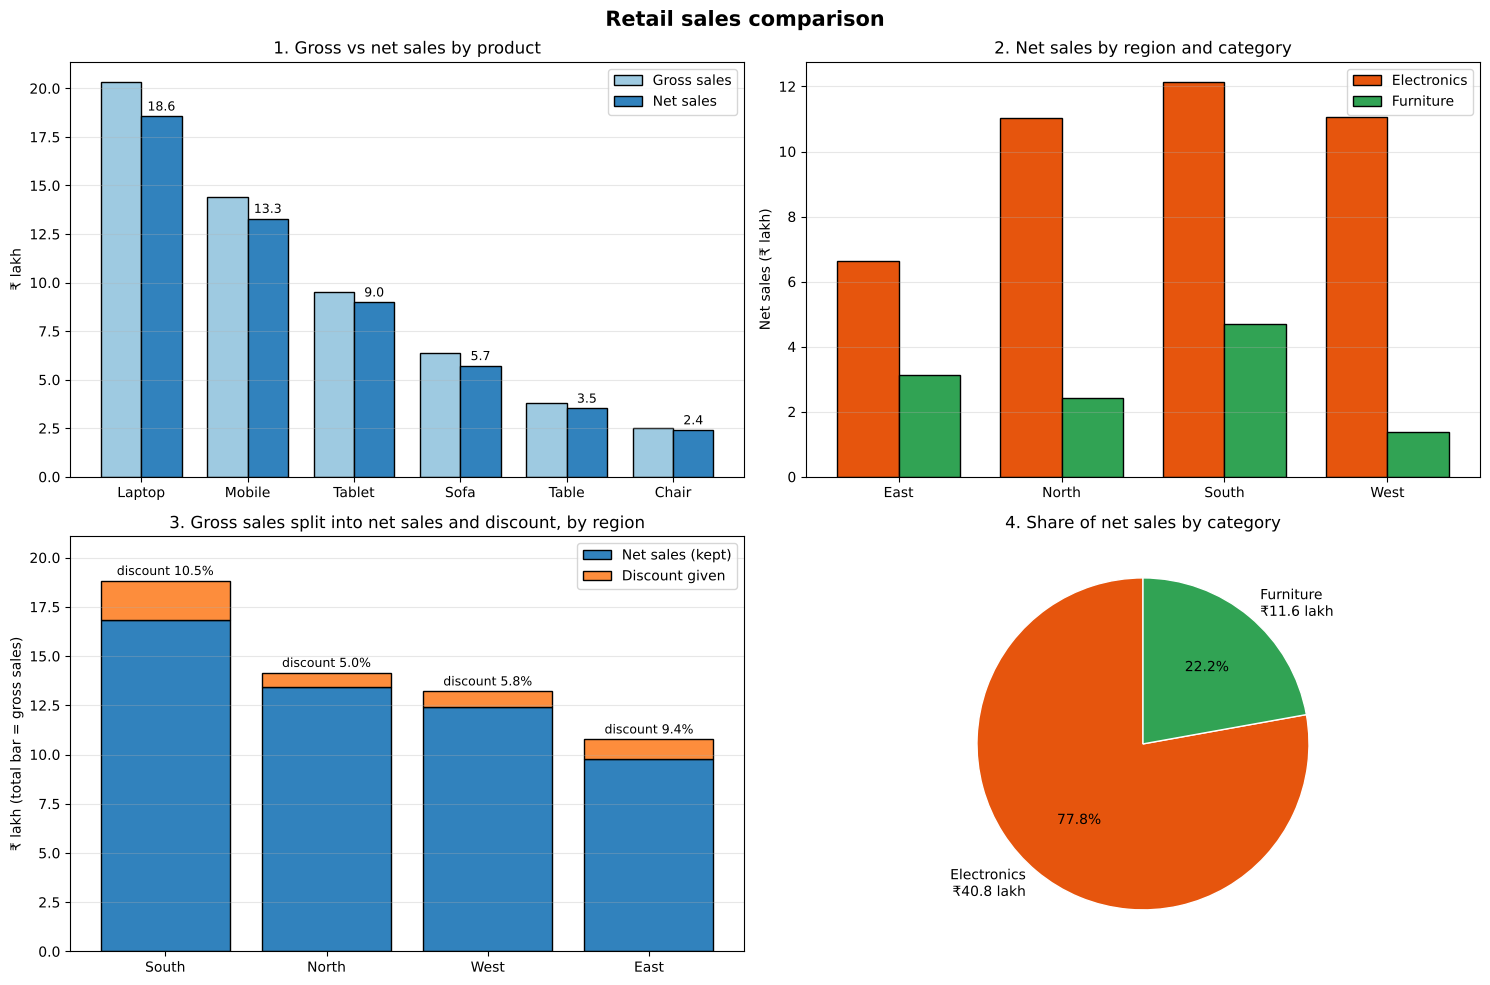

In [27]:
L = 1e5   # 1 lakh
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Gross vs net sales by product (grouped bar)
ax = axes[0, 0]
ps = product_summary.sort_values("Net_Sales", ascending=False)
x = np.arange(len(ps))
w = 0.38
ax.bar(x - w/2, ps["Gross_Sales"] / L, w, label="Gross sales", color="#9ecae1", edgecolor="black")
net_bars = ax.bar(x + w/2, ps["Net_Sales"] / L, w, label="Net sales", color="#3182bd", edgecolor="black")
ax.bar_label(net_bars, fmt="%.1f", padding=2, fontsize=9)     # value label on top of each net bar
ax.set_xticks(x)
ax.set_xticklabels(ps.index)
ax.set_ylabel("₹ lakh")
ax.set_title("1. Gross vs net sales by product")
ax.legend()
ax.grid(axis="y", alpha=0.3)

# 2. Net sales by region and category (grouped bar from the pivot table)
ax = axes[0, 1]
pv = pivot_net.drop(index="Total", columns="Total")
x = np.arange(len(pv))
ax.bar(x - w/2, pv["Electronics"] / L, w, label="Electronics", color="#e6550d", edgecolor="black")
ax.bar(x + w/2, pv["Furniture"] / L, w, label="Furniture", color="#31a354", edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(pv.index)
ax.set_ylabel("Net sales (₹ lakh)")
ax.set_title("2. Net sales by region and category")
ax.legend()
ax.grid(axis="y", alpha=0.3)

# 3. Stacked bar: net sales + discount = gross sales, by region
ax = axes[1, 0]
rs = region_summary
ax.bar(rs.index, rs["Net_Sales"] / L, label="Net sales (kept)", color="#3182bd", edgecolor="black")
ax.bar(rs.index, rs["Discount_Amt"] / L, bottom=rs["Net_Sales"] / L, label="Discount given", color="#fd8d3c", edgecolor="black")
for i, (n, d) in enumerate(zip(rs["Net_Sales"] / L, rs["Discount_Amt"] / L)):
    ax.text(i, n + d + 0.3, f"discount {rs['Effective_Disc_%'].iloc[i]:.1f}%", ha="center", fontsize=9)
ax.set_ylabel("₹ lakh (total bar = gross sales)")
ax.set_ylim(0, (rs["Gross_Sales"] / L).max() * 1.12)     # headroom for the labels
ax.set_title("3. Gross sales split into net sales and discount, by region")
ax.legend()
ax.grid(axis="y", alpha=0.3)

# 4. Pie chart of category share
ax = axes[1, 1]
cs = category_summary["Net_Sales"]
ax.pie(cs, labels=[f"{c}\n₹{v / L:.1f} lakh" for c, v in cs.items()], autopct="%1.1f%%",
       colors=["#e6550d", "#31a354"], startangle=90, wedgeprops={"edgecolor": "white"})
ax.set_title("4. Share of net sales by category")

plt.suptitle("Retail sales comparison", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

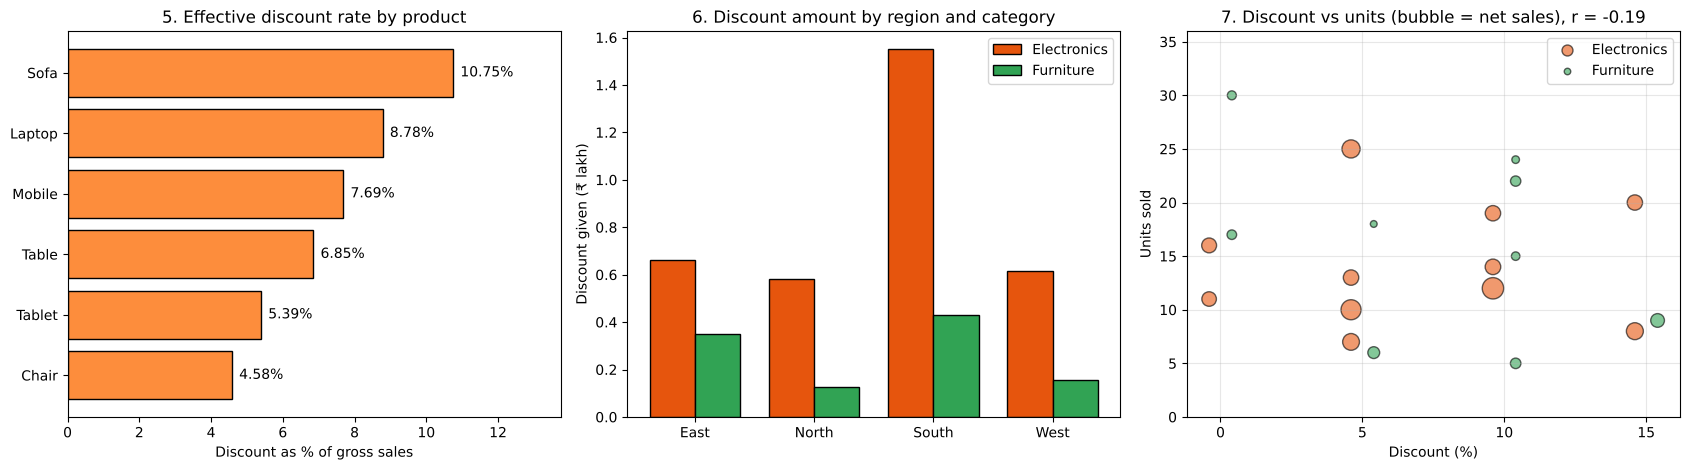

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 5. Effective discount % by product
ax = axes[0]
pdisc = product_summary["Effective_Disc_%"].sort_values()
ax.barh(pdisc.index, pdisc, color="#fd8d3c", edgecolor="black")
for i, v in enumerate(pdisc):
    ax.text(v + 0.2, i, f"{v:.2f}%", va="center")
ax.set_xlabel("Discount as % of gross sales")
ax.set_title("5. Effective discount rate by product")
ax.set_xlim(0, pdisc.max() + 3)

# 6. Discount amount by region and category (grouped)
ax = axes[1]
dpv = pd.pivot_table(df, values="Discount_Amt", index="Region", columns="Category", aggfunc="sum", fill_value=0)
x = np.arange(len(dpv))
ax.bar(x - w/2, dpv["Electronics"] / L, w, label="Electronics", color="#e6550d", edgecolor="black")
ax.bar(x + w/2, dpv["Furniture"] / L, w, label="Furniture", color="#31a354", edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(dpv.index)
ax.set_ylabel("Discount given (₹ lakh)")
ax.set_title("6. Discount amount by region and category")
ax.legend()

# 7. Scatter: discount % vs units sold, bubble size = net sales
ax = axes[2]
# Electronics is shifted slightly left and Furniture slightly right so bubbles at the same discount don't overlap
for cat, color, shift in [("Electronics", "#e6550d", -0.4), ("Furniture", "#31a354", 0.4)]:
    sub = df[df["Category"] == cat]
    ax.scatter(sub["Discount_Pct"] + shift, sub["Units"], s=sub["Net_Sales"] / 2500, alpha=0.6,
               color=color, edgecolor="black", label=cat)
r = df["Discount_Pct"].corr(df["Units"])
ax.set_xlabel("Discount (%)")
ax.set_ylabel("Units sold")
ax.set_title(f"7. Discount vs units (bubble = net sales), r = {r:.2f}")
ax.set_xticks([0, 5, 10, 15])
ax.set_ylim(0, 36)
ax.legend(loc="upper right", markerscale=0.6)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

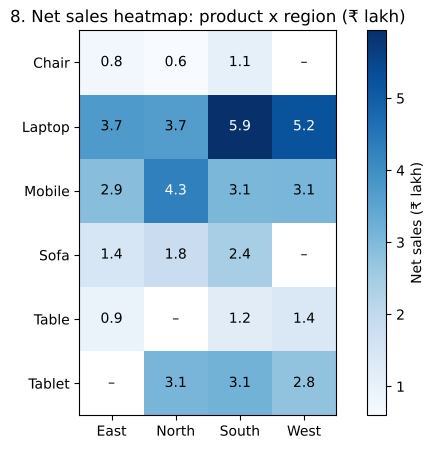

In [29]:
# Heatmap of the Product x Region pivot (blank = no sale of that product in that region)
pv2 = pd.pivot_table(df, values="Net_Sales", index="Product", columns="Region", aggfunc="sum") / L
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pv2.values, cmap="Blues")
ax.set_xticks(range(len(pv2.columns)))
ax.set_xticklabels(pv2.columns)
ax.set_yticks(range(len(pv2.index)))
ax.set_yticklabels(pv2.index)
for i in range(pv2.shape[0]):
    for j in range(pv2.shape[1]):
        v = pv2.values[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:.1f}", ha="center", va="center",
                color="white" if (not np.isnan(v) and v > 4) else "black")
fig.colorbar(im, label="Net sales (₹ lakh)")
ax.set_title("8. Net sales heatmap: product x region (₹ lakh)")
plt.show()

### Discount vs volume check
Did higher discounts lead to more units sold? We compare **average units per transaction** within each product, because products differ hugely in price (blank = no transaction at that discount level).

In [30]:
display(df.pivot_table(index="Product", columns="Discount_Pct", values="Units", aggfunc="mean"))
print("Correlation between discount % and units (all rows):", round(df["Discount_Pct"].corr(df["Units"]), 3))

Discount_Pct,0,5,10,15
Product,,,,
Chair,30.00,18.00,24.00,NaN
Laptop,NaN,8.50,12.00,8.00
Mobile,16.00,25.00,19.00,20.00
Sofa,NaN,6.00,5.00,9.00
Table,17.00,NaN,18.50,NaN
Tablet,11.00,13.00,14.00,NaN


Correlation between discount % and units (all rows): -0.188


## (h) Interpretation and business recommendations  *(10 marks)*

In [31]:
# Key figures used in the interpretation
south_disc_share = region_summary.loc["South", "Discount_Amt"] / df["Discount_Amt"].sum() * 100
print(f"South's share of all discount given  : {south_disc_share:.1f}%")
print(f"Avg net sales per transaction - Electronics: ₹{category_summary.loc['Electronics', 'Avg_Net_per_Txn']:,.0f}, "
      f"Furniture: ₹{category_summary.loc['Furniture', 'Avg_Net_per_Txn']:,.0f}")
print("Product-region combinations with NO sales:")
for prod, row in pivot_prod.drop(index="Total", columns="Total").iterrows():
    missing = row[row == 0].index.tolist()
    if missing:
        print(f"   {prod:7s}: {', '.join(missing)}")

South's share of all discount given  : 44.3%
Avg net sales per transaction - Electronics: ₹371,300, Furniture: ₹129,306
Product-region combinations with NO sales:
   Chair  : West
   Sofa   : West
   Table  : North
   Tablet : East


### Interpretation

1. **Revenue:** gross sales are **₹56.95 lakh**. Discounts take away **₹4.47 lakh (7.85%)**, leaving **₹52.48 lakh net sales**.
2. **Electronics dominates.** It brings in **77.8% of net sales (₹40.84 lakh)** from 11 of the 20 transactions. An average electronics transaction is worth about ₹3.71 lakh, against about ₹1.29 lakh for furniture. Unit volumes are almost equal (155 vs 146 units), so the gap comes from **price, not volume**.
3. **Products:**
   * **Laptop** is the top product (₹18.56 lakh, **35.4%** of net sales) despite only 37 units, and Laptop deals are the best transaction in three of the four regions.
   * **Mobile** sells the most units (80) and ranks 2nd in revenue (25.3%).
   * **Chair** sells many units (72) but earns the least (₹2.40 lakh, 4.6%). It is a low-value, high-volume item.
4. **Regions:**
   * **South** is the top region (₹16.84 lakh, 32.1%), but it also has the **highest effective discount (10.5%)** and accounts for **44% of all discount given**.
   * **North** ranks 2nd in sales with the **lowest discount (5%)**, so it is the most profitable mix.
   * **East** is the weakest region (₹9.76 lakh, 18.6%) even though it has the 2nd-highest discount rate (9.4%). Discounts there are not producing sales.
   * **West** sells electronics well but has the weakest furniture sales (₹1.39 lakh, Tables only).
5. **Discounts vs volume:** the correlation between discount % and units sold is **weak and negative (r = −0.19)**. In this data, bigger discounts did **not** lead to more units. **Sofa** receives the highest effective discount (10.75%) yet remains a low-volume product.
6. **Coverage gaps:** some products were not sold at all in some regions: Chair and Sofa in the West, Table in the North, Tablet in the East.

### Business recommendations

| # | Recommendation | Evidence |
|---|---|---|
| 1 | **Protect and grow Laptop and Mobile sales** with stock priority, bundles (laptop + accessories, mobile + tablet) and sales-staff focus. | Together 60.7% of net sales |
| 2 | **Review the discount policy in South and East.** Cap discounts (for example at 10%) and tie them to volume. | South gives 44% of all discount; East has a high discount but the lowest sales; r = −0.19 between discount and units |
| 3 | **Use North as the benchmark.** Study its sales approach, which gets strong revenue at only a 5% discount. | 2nd-highest sales at the lowest discount |
| 4 | **Raise furniture value per sale** by selling Chair/Table as sets with Sofa, cross-selling furniture with electronics (home-office bundles) and avoiding 15% Sofa discounts. | Furniture earns ₹1.29 lakh per transaction vs ₹3.71 lakh for electronics |
| 5 | **Fill regional gaps:** launch Chair/Sofa in the West, Tablet in the East and Table in the North. | No sales of these product-region pairs |
| 6 | **Track net sales and effective discount % monthly** in a dashboard (region × category pivot) to see whether these changes work. | |

*Caveat:* this is only 20 transactions, so patterns (especially the discount–volume correlation) should be confirmed with more data before making large decisions.